<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/agent_persona_bench_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Synthetic Persona Dataset Generator]
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"AgentPersonaBench Simulation Engine Initialized on: {device}")

class SyntheticPersonaGenerator:
    """
    Simulates multi-attribute latent persona profiles with embedded traits:
    - Budget-conscious vs. Luxury seeker
    - Concise responder vs. Elaborate storyteller
    - Quiet environment seeker vs. Social explorer
    """
    def __init__(self, num_personas: int = 200):
        self.num_personas = num_personas

    def generate_personas(self) -> list[dict]:
        personas = []
        for i in range(self.num_personas):
            is_budget = random.choice([True, False])
            is_concise = random.choice([True, False])
            prefers_quiet = random.choice([True, False])

            profile_text = f"User #{i+1}: "
            profile_text += "Carefully monitors monthly expenses and avoids overspending. " if is_budget else "Enjoys premium quality and luxury purchases. "
            profile_text += "Prefers direct, minimal, and brief communication. " if is_concise else "Enjoys detailed, long, and elaborate discussions. "
            profile_text += "Functions best in silent, calm, and distraction-free spaces." if prefers_quiet else "Thrives in vibrant, energetic social hubs."

            personas.append({
                'id': i + 1,
                'profile_text': profile_text,
                'traits': {
                    'budget_conscious': is_budget,
                    'concise_reply': is_concise,
                    'prefers_quiet': prefers_quiet
                }
            })
        return personas

generator = SyntheticPersonaGenerator(num_personas=200)
persona_dataset = generator.generate_personas()
print(f"Generated {len(persona_dataset)} Synthetic Persona Profiles.")
print(f"Sample Profile:\n{persona_dataset[0]['profile_text']}")

AgentPersonaBench Simulation Engine Initialized on: cuda
Generated 200 Synthetic Persona Profiles.
Sample Profile:
User #1: Carefully monitors monthly expenses and avoids overspending. Prefers direct, minimal, and brief communication. Thrives in vibrant, energetic social hubs.


In [2]:
# [CELL 2 - Multi-Surface Interaction Environment Simulator]

class MultiSurfaceAgentEnvironment:
    """
    Simulates agent behavior across 4 interaction surfaces:
    1. Survey Surface: Direct multiple-choice decision.
    2. Chat Surface: Text length compliance.
    3. Web Surface: Interactive e-commerce selection.
    4. App Surface: Desktop workflow configuration.
    """
    def __init__(self, noise_level: float = 0.15):
        self.noise_level = noise_level

    def execute_survey_surface(self, persona: dict) -> bool:
        """Task: Choose a reading location (Quiet Room vs Busy Lounge)."""
        target = persona['traits']['prefers_quiet']
        # Adherence drops slightly under unprompted conditions
        passed = target if random.random() > (self.noise_level * 0.5) else not target
        return passed == target

    def execute_chat_surface(self, persona: dict) -> bool:
        """Task: Respond to 'How was your trip?' (Brief vs Long reply)."""
        target = persona['traits']['concise_reply']
        passed = target if random.random() > (self.noise_level * 0.8) else not target
        return passed == target

    def execute_web_surface(self, persona: dict) -> bool:
        """Task: E-Commerce Desk Lamp Selection ($25 Budget vs $120 Luxury)."""
        target = persona['traits']['budget_conscious']
        # Higher environmental complexity increases decay
        passed = target if random.random() > (self.noise_level * 1.5) else not target
        return passed == target

    def execute_app_surface(self, persona: dict) -> bool:
        """Task: Desktop Workspace Setup (Low-resource/Minimalist vs Feature-heavy)."""
        target = persona['traits']['budget_conscious']
        # Highest operational complexity
        passed = target if random.random() > (self.noise_level * 2.2) else not target
        return passed == target

env = MultiSurfaceAgentEnvironment()
print("Multi-Surface Environment (Survey, Chat, Web, App) Initialized.")

Multi-Surface Environment (Survey, Chat, Web, App) Initialized.


In [4]:
# [CELL 3 - Benchmark Evaluation Pipeline & Modality Decay Measurement]

class AgentPersonaBenchEvaluator:
    def __init__(self, environment: MultiSurfaceAgentEnvironment, dataset: list[dict]):
        self.env = environment
        self.dataset = dataset

    def run_benchmark(self) -> tuple[dict[str, float], float]:
        surface_passes = {'Survey': 0, 'Chat': 0, 'Web': 0, 'App': 0}
        full_pass_count = 0
        total = len(self.dataset)

        for persona in self.dataset:
            p_survey = self.env.execute_survey_surface(persona)
            p_chat = self.env.execute_chat_surface(persona)
            p_web = self.env.execute_web_surface(persona)
            p_app = self.env.execute_app_surface(persona)

            if p_survey: surface_passes['Survey'] += 1
            if p_chat: surface_passes['Chat'] += 1
            if p_web: surface_passes['Web'] += 1
            if p_app: surface_passes['App'] += 1

            # Full-pass requires adhering across all 4 surfaces
            if p_survey and p_chat and p_web and p_app:
                full_pass_count += 1

        surface_acc = {k: (v / total) * 100.0 for k, v in surface_passes.items()}
        full_pass_rate = (full_pass_count / total) * 100.0
        return surface_acc, full_pass_rate

evaluator = AgentPersonaBenchEvaluator(env, persona_dataset)
surface_rates, full_pass = evaluator.run_benchmark()

print("\n--- AgentPersonaBench Evaluation Summary ---")
for surface, rate in surface_rates.items():
    print(f"  * {surface} Surface Pass Rate: {rate:.1f}%")
print(f"  * Overall 4-Surface Full-Pass Rate: {full_pass:.1f}%")


--- AgentPersonaBench Evaluation Summary ---
  * Survey Surface Pass Rate: 92.5%
  * Chat Surface Pass Rate: 87.5%
  * Web Surface Pass Rate: 79.5%
  * App Surface Pass Rate: 68.5%
  * Overall 4-Surface Full-Pass Rate: 44.5%


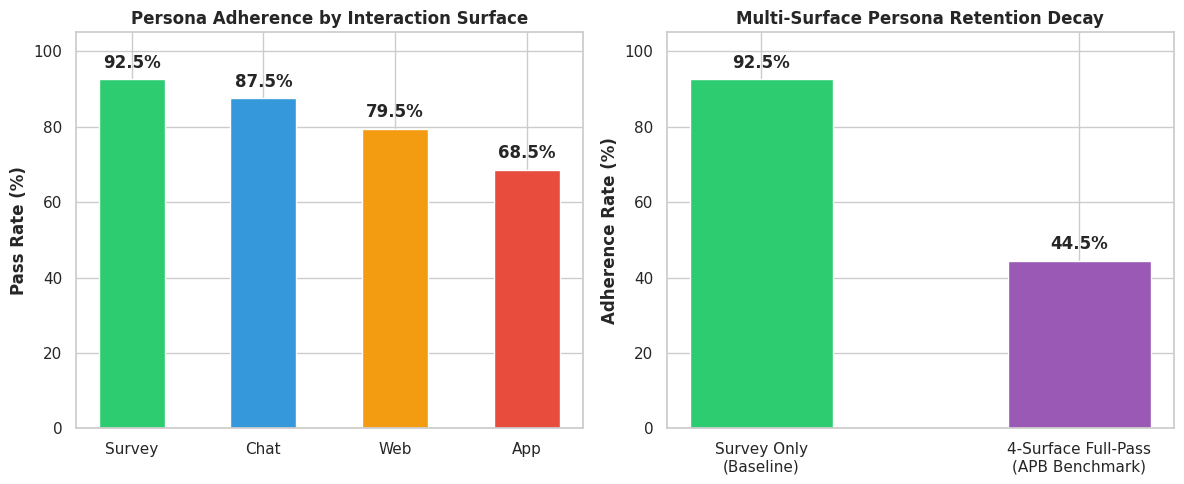

AgentPersonaBench visualization saved successfully as agent_persona_bench_results.png.


In [5]:
# [CELL 4 - Multi-Panel Visualization of Multi-Surface Persona Decay]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Adherence Rate across Interaction Surfaces
surfaces = list(surface_rates.keys())
rates = list(surface_rates.values())

bars1 = ax1.bar(surfaces, rates, color=['#2ecc71', '#3498db', '#f39c12', '#e74c3c'], width=0.5)
ax1.set_title("Persona Adherence by Interaction Surface", fontweight='bold')
ax1.set_ylabel("Pass Rate (%)", fontweight='bold')
ax1.set_ylim(0, 105)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

# Plot 2: Full-Pass Adherence Comparison (Single Surface vs 4-Surface Full Pass)
comparison_labels = ['Survey Only\n(Baseline)', '4-Surface Full-Pass\n(APB Benchmark)']
comp_rates = [surface_rates['Survey'], full_pass]

bars2 = ax2.bar(comparison_labels, comp_rates, color=['#2ecc71', '#9b59b6'], width=0.45)
ax2.set_title("Multi-Surface Persona Retention Decay", fontweight='bold')
ax2.set_ylabel("Adherence Rate (%)", fontweight='bold')
ax2.set_ylim(0, 105)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("agent_persona_bench_results.png", dpi=300)
plt.show()

print("AgentPersonaBench visualization saved successfully as agent_persona_bench_results.png.")